# Lab 10: Video Analysis and Object Tracking
**ITAI 1378 Computer Vision | Houston City College | AI and Robotics Program**
**Module 10: Video Analysis and Object Tracking | Instructor: Patricia McManus**

> **Bonus lab (optional).** After Module 08, every lab in ITAI 1378 is a **bonus** lab. It is not mandatory, and skipping it will not lower your grade. Completing it earns bonus credit.

Welcome! A detector finds objects in **one** frame. A tracker **connects** those detections across frames and gives each one a track ID, so you can ask questions about time: how long did someone stay in a zone, how many people passed, where did they go?

This lab follows the Module 10 lab plan: **one camera, one baseline, one change.**
1. Use one short clip (about 30 seconds) from one camera.
2. Run a fixed detector with an explicitly selected tracker (**ByteTrack**) and save the baseline.
3. Change **one** tracker setting, reset the tracker, and rerun the same clip with everything else held fixed.
4. Compare the same timestamps in both runs and explain the errors you see: missed detections, false positives, ID changes, and any change in a zone event.

Honest results earn full credit. If your change does not improve anything, or you see no clear failure, say so. Do not invent an error.

**Before you start:** File > Save a copy in Drive, then rename your copy `Lab_10_LastName_FirstName_ITAI1378.ipynb`. The free Colab CPU runtime is enough. Each tracking run takes about 1 to 3 minutes.

## Part 1: Setup

In [1]:
%pip install -q ultralytics opencv-python-headless lap

In [2]:
import os, time, json, copy, urllib.request
import cv2, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ultralytics
from ultralytics import YOLO
from ultralytics.utils import ROOT

MODEL_NAME = "yolov8n.pt"      # fixed detector: do not change it between runs
print("Ultralytics version:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.215


## Part 2: Key ideas
- **Detection** answers "what is in this frame and where?" **Tracking** answers "is this the same object I saw a moment ago?"
- **Tracking by detection:** every analyzed frame, the detector finds boxes. The tracker predicts where each existing track should be, then matches new boxes to tracks (ByteTrack uses box motion and overlap). Unmatched boxes may start new tracks. Tracks that go unmatched are kept alive for a while (the **track buffer**) and then deleted.
- **A track ID is not an identity.** ID 7 means "the tracker believes these boxes belong together". It does not know who the person is, and it can be wrong.
- **Capture rate vs. analysis rate:** a camera may record 60 frames per second, but you may only analyze 10 of them. Fewer frames means less compute, but objects move farther between looks, which makes matching harder.
- **Common errors:** a *missed detection* (the person is there, no box), a *false positive* (a box with no person), an *ID switch* (two people swap IDs), and *fragmentation* (one person's track breaks and comes back with a new ID).

## Part 3: The clip and the analysis rate
We use a public sample video of workers in a work area (Intel open sample videos). We analyze a 30 second window starting at `CLIP_START` seconds, chosen because two workers are on screen together and IDs change hands, which gives us a challenging interval.

Capture rate: 59.94 FPS | frame size 1920x1080 | clip: 28 s to 58 s


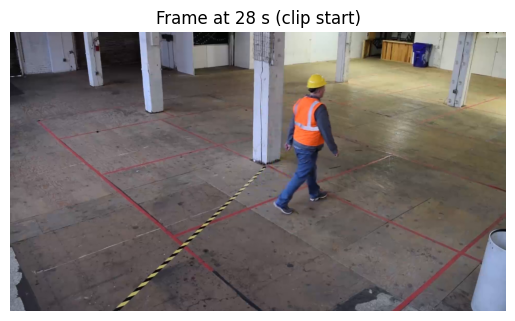

In [3]:
VIDEO_URL = "https://github.com/intel-iot-devkit/sample-videos/raw/master/worker-zone-detection.mp4"
VIDEO_PATH = "workers.mp4"
if not os.path.exists(VIDEO_PATH):
    urllib.request.urlretrieve(VIDEO_URL, VIDEO_PATH)

CLIP_START, CLIP_SECONDS = 28, 30
cap = cv2.VideoCapture(VIDEO_PATH)
CAPTURE_FPS = cap.get(cv2.CAP_PROP_FPS)
START_FRAME, END_FRAME = int(CLIP_START * CAPTURE_FPS), int((CLIP_START + CLIP_SECONDS) * CAPTURE_FPS)
for _ in range(START_FRAME + 1):
    ok, first_frame = cap.read()
cap.release()
H, W = first_frame.shape[:2]
print(f"Capture rate: {CAPTURE_FPS:.2f} FPS | frame size {W}x{H} | clip: {CLIP_START} s to {CLIP_START + CLIP_SECONDS} s")
plt.imshow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.title(f"Frame at {CLIP_START} s (clip start)"); plt.show()

### TODO 1: Choose the analysis rate
We will analyze `ANALYSIS_FPS = 10` frames per second. Finish `analysis_stride` so it returns how many captured frames to step between analyzed frames (for 60 FPS capture and 10 FPS analysis that is 6). Round to the nearest whole number.

In [4]:
ANALYSIS_FPS = 10

def analysis_stride(capture_fps, analysis_fps):
    # TODO 1: One analyzed frame for every six captured frames at 60/10 FPS.
    return round(capture_fps / analysis_fps)

STRIDE = analysis_stride(CAPTURE_FPS, ANALYSIS_FPS)
print(f"Analyze 1 of every {STRIDE} frames -> {CAPTURE_FPS / STRIDE:.1f} analyzed frames per second, "
      f"{int(CLIP_SECONDS * CAPTURE_FPS / STRIDE)} frames per run")
assert analysis_stride(60, 10) == 6

Analyze 1 of every 6 frames -> 10.0 analyzed frames per second, 299 frames per run


## Part 4: Detection alone has no memory
Run the detector on two analyzed frames in a row (at about 35 seconds). Notice there are boxes, but nothing says which box in frame A is the same person in frame B.

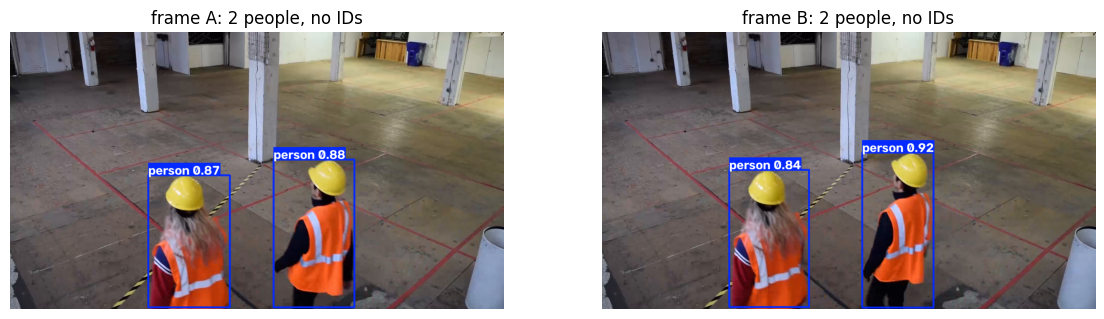

In [5]:
detector = YOLO(MODEL_NAME)
cap = cv2.VideoCapture(VIDEO_PATH)
frames = []
for i in range(int(35 * CAPTURE_FPS) + STRIDE + 1):
    ok, f = cap.read()
    if i in (int(35 * CAPTURE_FPS), int(35 * CAPTURE_FPS) + STRIDE):
        frames.append(f)
cap.release()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, f, name in zip(axes, frames, ["frame A", "frame B"]):
    r = detector(f, classes=[0], verbose=False)[0]
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); ax.axis("off"); ax.set_title(f"{name}: {len(r.boxes)} people, no IDs")
plt.show()

## Part 5: The baseline run (ByteTrack with its default settings)
We load the documented ByteTrack defaults that ship with Ultralytics and save them to our own file, so the configuration is written down and explicit.

`run_tracker` creates a **fresh model each time**, which resets the tracker state. It records one row per tracked box: the time, the track ID, the box, and the confidence. It also measures how long each analyzed frame takes to process.

In [6]:
with open(ROOT / "cfg" / "trackers" / "bytetrack.yaml") as f:
    BASELINE_CFG = yaml.safe_load(f)
with open("baseline_bytetrack.yaml", "w") as f:
    yaml.safe_dump(BASELINE_CFG, f)
print("Baseline ByteTrack settings:")
for k, v in BASELINE_CFG.items():
    print(f"  {k}: {v}")

THUMBS = {}

def run_tracker(tracker_file, label):
    model = YOLO(MODEL_NAME)                    # fresh model = fresh tracker state
    cap = cv2.VideoCapture(VIDEO_PATH)
    rows, frame_idx, times_ms = [], -1, []
    while True:
        ok, frame = cap.read()
        frame_idx += 1
        if not ok or frame_idx >= END_FRAME:
            break
        if frame_idx < START_FRAME or (frame_idx - START_FRAME) % STRIDE:
            continue
        if frame_idx not in THUMBS:                 # small copies so we can look back at any analyzed frame
            THUMBS[frame_idx] = cv2.imencode(".jpg", cv2.resize(frame, (W // 2, H // 2)))[1]
        t0 = time.perf_counter()
        r = model.track(frame, persist=True, tracker=tracker_file, classes=[0], verbose=False)[0]
        times_ms.append((time.perf_counter() - t0) * 1000)
        if r.boxes.id is None:
            continue
        for box, tid, conf in zip(r.boxes.xyxy.tolist(), r.boxes.id.int().tolist(), r.boxes.conf.tolist()):
            rows.append({"run": label, "frame": frame_idx, "time_s": round(frame_idx / CAPTURE_FPS, 2),
                         "track_id": tid, "x1": box[0], "y1": box[1], "x2": box[2], "y2": box[3], "conf": conf})
    cap.release()
    print(f"{label}: {len(times_ms)} frames analyzed, median {np.median(times_ms):.0f} ms per frame, "
          f"p95 {np.percentile(times_ms, 95):.0f} ms")
    return pd.DataFrame(rows), times_ms

baseline, baseline_ms = run_tracker("baseline_bytetrack.yaml", "baseline")
baseline.head()

Baseline ByteTrack settings:
  tracker_type: bytetrack
  track_high_thresh: 0.25
  track_low_thresh: 0.1
  new_track_thresh: 0.25
  track_buffer: 30
  match_thresh: 0.8
  fuse_score: True
baseline: 300 frames analyzed, median 112 ms per frame, p95 183 ms


,run,frame,time_s,track_id,x1,y1,x2,y2,conf
0,baseline,1678,27.99,1,1026.040405,159.609253,1272.268188,706.357605,0.894072
1,baseline,1684,28.09,1,1047.898926,156.762527,1287.333252,690.205933,0.861460
2,baseline,1690,28.19,1,1090.471313,152.518036,1319.422119,667.571289,0.884535
3,baseline,1696,28.29,1,1124.509644,151.101990,1347.214600,657.423767,0.899708
4,baseline,1702,28.40,1,1153.317505,148.111893,1374.008301,650.677551,0.862887


### TODO 2: Summarize the tracks
Finish `summarize` so it returns a table with one row per track ID showing `first_s` (first time seen), `last_s` (last time seen), `duration_s` (last minus first), and `n_boxes`. Then we count **short tracks** (under 1 second). Short tracks are often fragments or false positives, so they are good places to look for errors.

In [7]:
def summarize(df):
    # TODO 2: Group all boxes with the same track ID.
    s = df.groupby("track_id").agg(
        first_s=("time_s", "min"),
        last_s=("time_s", "max"),
        n_boxes=("time_s", "count"),
    )
    s["duration_s"] = s["last_s"] - s["first_s"]
    return s[["first_s", "last_s", "duration_s", "n_boxes"]]

def report(df, label):
    s = summarize(df)
    print(f"{label}: {len(s)} unique track IDs | {int((s['duration_s'] < 1).sum())} short tracks (< 1 s)")
    return s

base_summary = report(baseline, "baseline")
base_summary

baseline: 4 unique track IDs | 0 short tracks (< 1 s)


,first_s,last_s,duration_s,n_boxes
track_id,,,,
1,27.99,30.80,2.81,29
3,34.10,43.21,9.11,92
4,34.30,43.91,9.61,97
6,48.01,55.82,7.81,79


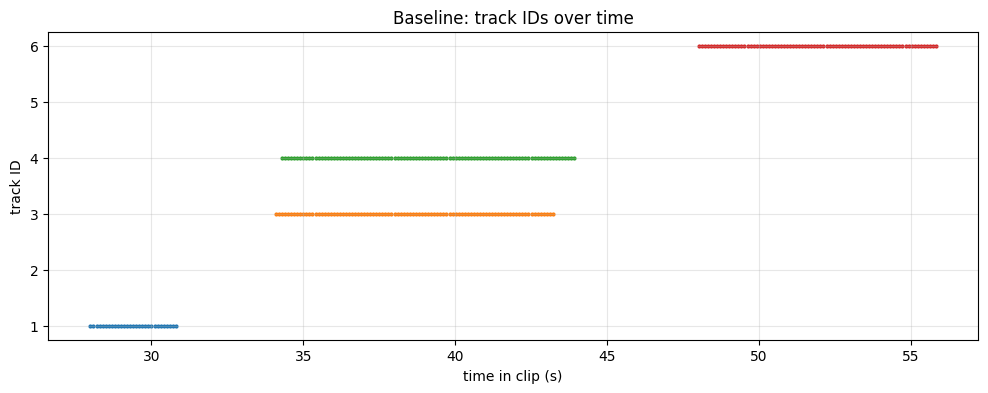

In [8]:
def plot_timeline(df, title):
    """Each horizontal line is one track ID. Gaps and short lines are worth a closer look."""
    plt.figure(figsize=(12, 4))
    for tid, g in df.groupby("track_id"):
        plt.scatter(g["time_s"], [tid] * len(g), s=4)
    plt.xlabel("time in clip (s)"); plt.ylabel("track ID"); plt.title(title); plt.grid(alpha=0.3); plt.show()

plot_timeline(baseline, "Baseline: track IDs over time")

## Part 6: Change one setting
Here are three ByteTrack settings worth testing. Each one controls a different part of the tracking loop:
- `match_thresh` (default 0.8): how loose the match between a predicted track and a new box may be. **Lower is stricter**, so tracks break more easily.
- `track_buffer` (default 30): how many **analyzed** frames a lost track is kept alive, waiting for its object to come back. At 10 analyzed frames per second, 30 is about 3 seconds.
- `track_high_thresh` (default 0.25): how confident a detection must be to be matched in the first round.

### TODO 3: Make exactly one change
Copy the baseline settings and change **only one** of them. A good first try is `match_thresh = 0.5`. You may instead try `track_buffer` (5 or 90) or `track_high_thresh` (0.6). If your change makes no visible difference (for example, `track_buffer` matters only when someone disappears for a while), that is a valid finding: report it honestly. The check below makes sure only one setting differs.

Settings that differ from the baseline: {'match_thresh': (0.8, 0.5)}
changed: 300 frames analyzed, median 115 ms per frame, p95 186 ms
changed: 14 unique track IDs | 8 short tracks (< 1 s)


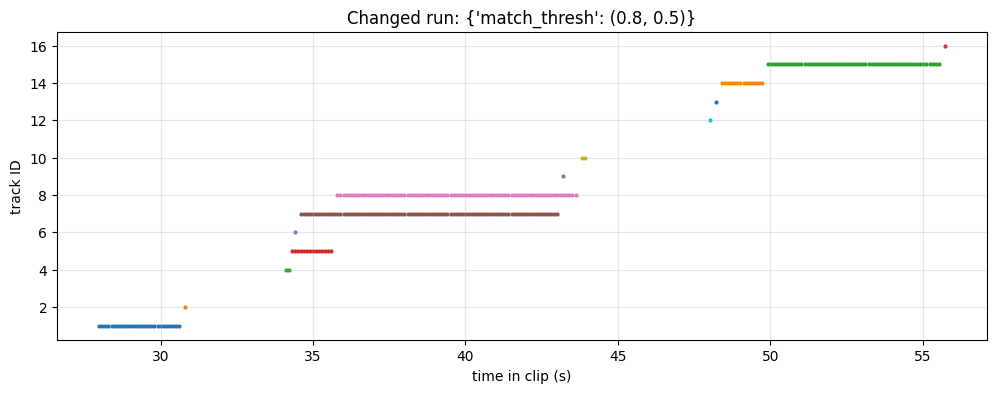

In [9]:
CHANGED_CFG = copy.deepcopy(BASELINE_CFG)
# TODO 3: Change exactly one ByteTrack setting and keep everything else fixed.
CHANGED_CFG["match_thresh"] = 0.5

diff = {k: (BASELINE_CFG[k], CHANGED_CFG[k]) for k in BASELINE_CFG if BASELINE_CFG[k] != CHANGED_CFG[k]}
print("Settings that differ from the baseline:", diff)
assert len(diff) == 1, "Change exactly ONE setting so the comparison is fair."
with open("changed_bytetrack.yaml", "w") as f:
    yaml.safe_dump(CHANGED_CFG, f)

changed, changed_ms = run_tracker("changed_bytetrack.yaml", "changed")
changed_summary = report(changed, "changed")
plot_timeline(changed, f"Changed run: {diff}")

## Part 7: Compare the same timestamps
Use the two timelines to pick moments where something happens: a line that breaks, a new ID that appears, or a short track. Then look at the **same** timestamps in both runs side by side.

### TODO 4: Choose your timestamps
Replace the example times with two or three timestamps (in seconds) you want to inspect.

34.5 s | baseline: 2 tracked boxes, IDs [3, 4]
34.5 s | changed: 1 tracked boxes, IDs [5]


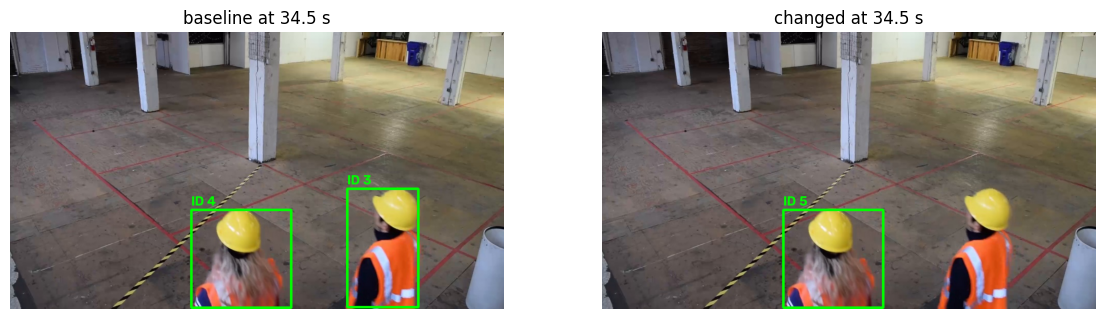

43.5 s | baseline: 1 tracked boxes, IDs [4]
43.5 s | changed: 1 tracked boxes, IDs [8]


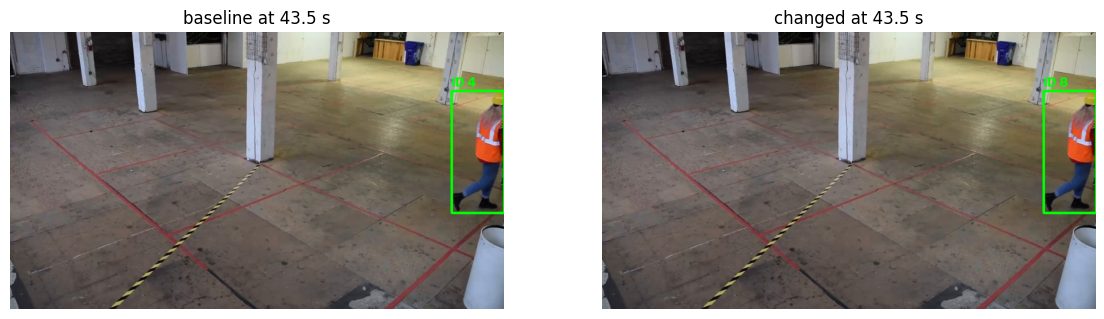

52.5 s | baseline: 1 tracked boxes, IDs [6]
52.5 s | changed: 1 tracked boxes, IDs [15]


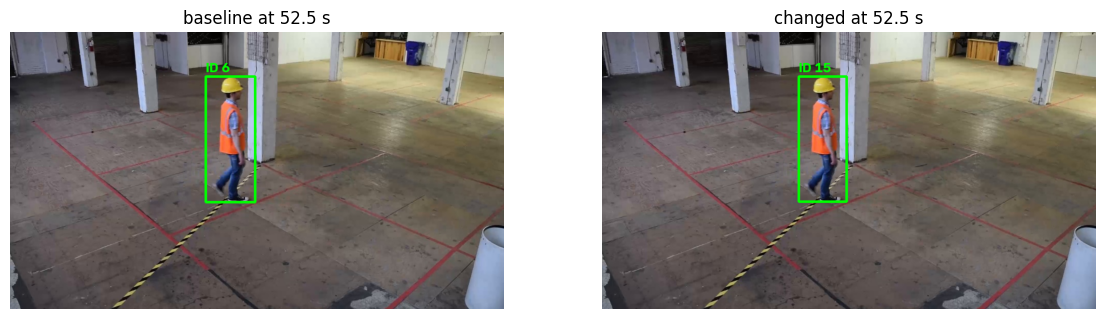

In [10]:
# TODO 4: Three different timestamps across the clip (not the starter examples).
# Compare the same frames in both runs after checking the two timelines.
TIMES_TO_CHECK = [34.5, 43.5, 52.5]

def frame_at(t):
    idx = min(THUMBS, key=lambda k: abs(k / CAPTURE_FPS - t))
    return idx, cv2.imdecode(THUMBS[idx], cv2.IMREAD_COLOR)

def draw(df, frame_idx, img):
    img = img.copy()
    for _, r in df[df["frame"] == frame_idx].iterrows():
        p1, p2 = (int(r.x1 / 2), int(r.y1 / 2)), (int(r.x2 / 2), int(r.y2 / 2))
        cv2.rectangle(img, p1, p2, (0, 255, 0), 3)
        cv2.putText(img, f"ID {int(r.track_id)}", (p1[0], max(20, p1[1] - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

for t in TIMES_TO_CHECK:
    idx, img = frame_at(t)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for ax, df, name in zip(axes, [baseline, changed], ["baseline", "changed"]):
        ax.imshow(draw(df, idx, img))
        ax.axis("off")
        ax.set_title(f"{name} at {idx / CAPTURE_FPS:.1f} s")
        tids = sorted(df.loc[df["frame"] == idx, "track_id"].astype(int).tolist())
        print(f"{idx / CAPTURE_FPS:.1f} s | {name}: {len(tids)} tracked boxes, IDs {tids}")
    plt.show()

**Reflection 1 (error diagnosis):** For each timestamp you checked, write one line per run using the error vocabulary: missed detection, false positive, ID switch, fragmentation, or "no visible error". Example: *"12.4 s, baseline: worker behind the shelf returns as a new ID (fragmentation). Changed: keeps ID 3."* If the video does not show enough to decide, say that.

*Your answer:*

**34.5 s, baseline:** No visible error. The tracker detected both workers and gave them IDs 3 and 4.

**34.5 s, changed:** Missed detection. The tracker detected only one worker and missed the person on the right.

**43.5 s, baseline:** No visible error. The tracker detected the worker near the right edge with ID 4.

**43.5 s, changed:** No visible error. The tracker detected the same worker with ID 8.

**52.5 s, baseline:** No visible error. The tracker detected one worker with ID 6.

**52.5 s, changed:** No visible error. The tracker detected the same worker with ID 15.

The biggest difference I noticed was the missed detection at 34.5 seconds. Both runs detected the visible workers at the other timestamps. I couldn't confirm any ID switches or fragmentation from these screenshots alone.

## Part 8: A zone event
Trackers matter because they let us measure events over time. Here the event is **dwell time**: how long each track stays inside a rectangular zone. We use the bottom center of each box (the feet).

### TODO 5: Compute dwell time per track
1. Finish `in_zone`.
2. In `dwell_times`, keep only the rows inside the zone, then count rows per `track_id`. Each analyzed frame represents `STRIDE / CAPTURE_FPS` seconds, so multiply the count by that.

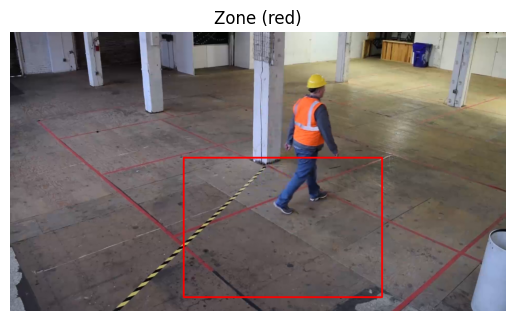

baseline: 4 track IDs entered the zone | total dwell 10.8 s
   dwell by ID (s): {1: 1.0, 3: 4.8, 4: 2.7, 6: 2.3}
changed: 4 track IDs entered the zone | total dwell 10.8 s
   dwell by ID (s): {1: 1.0, 7: 4.8, 8: 2.7, 15: 2.3}


In [15]:
ZONE = (int(W * 0.35), int(H * 0.45), int(W * 0.75), int(H * 0.95))   # x1, y1, x2, y2 (you may move it)

def in_zone(px, py, zone=ZONE):
    x1, y1, x2, y2 = zone
    return x1 <= px <= x2 and y1 <= py <= y2

def dwell_times(df):
    feet_x = (df["x1"] + df["x2"]) / 2
    feet_y = df["y2"]
    inside = df[[in_zone(x, y) for x, y in zip(feet_x, feet_y)]]
    return inside.groupby("track_id").size() * (STRIDE / CAPTURE_FPS)

preview = first_frame.copy()
cv2.rectangle(preview, ZONE[:2], ZONE[2:], (0, 0, 255), 6)
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.title("Zone (red)"); plt.show()

for name, df in [("baseline", baseline), ("changed", changed)]:
    d = dwell_times(df)
    print(f"{name}: {len(d)} track IDs entered the zone | total dwell {d.sum():.1f} s")
    print("   dwell by ID (s):", {int(k): round(float(v), 1) for k, v in d.items()})

**Reflection 2 (zone event):** Did the number of IDs in the zone or the dwell times change between runs? If one person's track broke into two IDs, what does that do to a dwell time report? Which is more harmful for **this** task: a broken track (fragmentation) or two people sharing one ID (a wrong reconnection)? Explain.

*Your answer:*

 - After fixing the zone detection, both runs counted 4 track IDs inside the restricted zone, with a total dwell time of 10.8 seconds each. The IDs were different between the runs, but the total time stayed the same. This showed me that changing the tracker setting didn't affect the overall dwell time in this test. If one person's track breaks into two IDs, the system might split their time into separate visits and make the report confusing. However, I think two people sharing the same ID would create a bigger problem because the system could combine their time and make it look like one person stayed longer than they actually did. Both problems could make the results less reliable, especially if someone used them to evaluate workers.

## Part 9: Write down your configuration
A result nobody can reproduce is hard to trust. Finish the record below. Fill in the text fields in your own words.

### TODO 6: Complete the configuration record

In [16]:
# TODO 6: Keep an exact configuration record and explain the results and limits.

# Calculate dwell times for both runs
baseline_dwell = dwell_times(baseline)
changed_dwell = dwell_times(changed)

base_ids = len(base_summary)
new_ids = len(changed_summary)
base_short = int((base_summary["duration_s"] < 1).sum())
new_short = int((changed_summary["duration_s"] < 1).sum())

record = {
    "clip": f"{VIDEO_URL} ({CLIP_START} s to {CLIP_START + CLIP_SECONDS} s)",
    "capture_fps": round(CAPTURE_FPS, 2),
    "analysis_fps": round(CAPTURE_FPS / STRIDE, 2),
    "detector": MODEL_NAME,
    "classes": ["person"],
    "ultralytics_version": ultralytics.__version__,
    "tracker": "ByteTrack",
    "baseline_settings": BASELINE_CFG,
    "one_change": diff,
    "median_ms_per_frame": {
        "baseline": round(float(np.median(baseline_ms))),
        "changed": round(float(np.median(changed_ms)))
    },
    "what_changed_in_the_results": (
        f"I changed only match_thresh from {BASELINE_CFG['match_thresh']} to {CHANGED_CFG['match_thresh']}. "
        f"The baseline produced {base_ids} track IDs, including {base_short} tracks shorter than one second. "
        f"The changed run produced {new_ids} track IDs, including {new_short} short tracks. "
        f"The number of zone IDs went from {len(baseline_dwell)} to {len(changed_dwell)}. "
        "These counts show differences, but they do not prove which run followed people more accurately."
    ),
    "limits_of_this_test": (
        "I only tested one 30-second clip and did not check the track IDs against ground-truth identities. "
        "Occlusion, camera angles, lighting, and the 10 FPS analysis rate could affect the results."
    ),
}
print(json.dumps(record, indent=2, default=str))
with open("lab10_config_record.json", "w") as f:
    json.dump(record, f, indent=2, default=str)

# Use these actual timings when finishing Reflection 3.
for name, ms in [("baseline", baseline_ms), ("changed", changed_ms)]:
    median, p95 = float(np.median(ms)), float(np.percentile(ms, 95))
    print(f"{name}: median {median:.1f} ms, p95 {p95:.1f} ms; "
          f"{'meets' if median < 100 and p95 < 100 else 'does not consistently meet'} the 100 ms/frame target")

{
  "clip": "https://github.com/intel-iot-devkit/sample-videos/raw/master/worker-zone-detection.mp4 (28 s to 58 s)",
  "capture_fps": 59.94,
  "analysis_fps": 9.99,
  "detector": "yolov8n.pt",
  "classes": [
    "person"
  ],
  "ultralytics_version": "8.4.215",
  "tracker": "ByteTrack",
  "baseline_settings": {
    "tracker_type": "bytetrack",
    "track_high_thresh": 0.25,
    "track_low_thresh": 0.1,
    "new_track_thresh": 0.25,
    "track_buffer": 30,
    "match_thresh": 0.8,
    "fuse_score": true
  },
  "one_change": {
    "match_thresh": [
      0.8,
      0.5
    ]
  },
  "median_ms_per_frame": {
    "baseline": 112,
    "changed": 115
  },
  "what_changed_in_the_results": "I changed only match_thresh from 0.8 to 0.5. The baseline produced 4 track IDs, including 0 tracks shorter than one second. The changed run produced 14 track IDs, including 8 short tracks. The number of zone IDs went from 4 to 4. These counts show differences, but they do not prove which run followed people 

**Reflection 3 (speed):** Your run printed a median and p95 time per analyzed frame. At 10 analyzed frames per second, each frame must finish in under 100 ms to keep up. Did yours? Why is "it runs online" not the same as "it runs in real time"?

*Your answer:*

 - My runs did not meet the 100 ms per frame target. The baseline had a median processing time of 112.2 ms and a p95 of 183.4 ms, while the changed run had a median of 115.0 ms and a p95 of 185.8 ms. The changed version was slightly slower, but neither run could consistently keep up with 10 analyzed frames per second. This showed me that even a small delay can matter when a system needs to process video continuously. Running the notebook online in Google Colab doesn't mean the system works in real time. Colab processes the video on its own schedule, while a real-time system needs to keep up with incoming frames. I think using a faster device or reducing the analysis rate could improve performance.

## Part 10: Wrap-up questions
Answer each in about 75 to 150 words, in your own words.

1. **Detection vs. tracking:** Explain the difference using something you saw in this lab. Why should a report never treat a track ID as a person's identity?

- Detection and tracking serve different purposes in computer vision. Detection finds objects in individual frames, while tracking follows those objects across multiple frames and gives them IDs. In this lab, I could see how ByteTrack followed workers as they moved around the warehouse. For example, at 34.5 seconds, the baseline detected two workers with IDs 3 and 4, while the changed version only detected one. Tracking helps us understand movement over time, but a track ID doesn't represent someone's actual identity. The system can assign a new ID when it loses track of a person, especially if something blocks the camera's view. Because of this, I wouldn't use track IDs to identify specific workers without additional verification.

2. **Your controlled comparison:** What one setting did you change, what did it fix or break, and what would you try next? Remember: changing several settings at once makes it impossible to tell which one mattered.

- For my comparison, I changed only the match_thresh setting from 0.8 to 0.5 and kept everything else the same. I wanted to see whether this adjustment would help ByteTrack follow workers more consistently. However, I didn't notice a clear improvement. At 34.5 seconds, the baseline detected two workers, while the changed version missed one of them. At the other timestamps I checked, both versions detected the visible workers, although they used different track IDs. This showed me that changing one setting doesn't always improve the results. Next, I would test another value for match_thresh while keeping the other settings unchanged. I would also compare more timestamps and videos to understand whether the change actually helps.

3. **Would you trust it here?** A warehouse manager wants to use this exact setup to measure how long each worker spends at a packing station and use it in performance reviews. Would you recommend it? What evidence, limits, and human decisions would you require first?

- I wouldn't recommend using this system for employee performance reviews without more testing. In my lab, both versions counted 4 track IDs inside the restricted zone and recorded 10.8 seconds of total dwell time. However, getting the same numbers doesn't necessarily mean the system tracked everyone correctly. Tracking errors could make a worker appear to spend more or less time at a station than they actually did. Before using the system, I would test it with different camera angles, lighting conditions, and videos where I could check the real results. I would also want a human to review the information before making decisions about employees. I think this technology could help managers understand general workplace activity, but it shouldn't determine someone's performance on its own.

---
**Submit:** Runtime > Restart session and run all. Then File > Download > Download .ipynb and upload `Lab_10_LastName_FirstName_ITAI1378.ipynb` to the Lab 10 (Bonus) assignment in Canvas. Make sure the timelines, side by side frames, and printed results are visible.

If you used an AI assistant to help with an error or a concept, add one sentence at the end saying what you used it for.

**AI usage note:** I used ChatGPT to help me understand Python code and troubleshoot coding issues.